# How Deep Is Too Deep?  

**Does increasing neural network depth improve classification performance, or does it introduce diminishing returns in learning efficiency and generalization?**

*Deep learning portfolio experiment · Fashion-MNIST · PyTorch*

More layers may let a neural network build complex representations, but they also add parameters, computation, and extra steps for gradients. Does depth help a small image-classification task, or do extra layers eventually offer less benefit than their cost?

In this experiment, I compare fully connected neural networks with one to four hidden layers on Fashion-MNIST. I will keep the training recipe fixed and change only the number of hidden layers. The aim is not to find the highest possible accuracy, but to observe how depth changes learning curves, validation performance, and training time.

## What does network depth mean?

A neural network is built from layers of connected neurons. Each layer transforms the representation it receives. In a fully connected layer, every neuron receives input from every neuron in the previous layer, applies a weighted sum plus a bias, and then (for hidden layers) passes the result through an activation function.

The **depth** in this post means the number of hidden layers; the output layer is not counted. A shallow network performs fewer transformations. A deeper network can compose more transformations, potentially learning useful intermediate representations. Depth is an architectural hyperparameter because it is selected before training and describes the model's structure.

For a hidden layer, the operation can be written as:

\[
\mathbf{h}^{(l)} = \operatorname{ReLU}(\mathbf{W}^{(l)}\mathbf{h}^{(l-1)} + \mathbf{b}^{(l)})
\]

Here, \(\mathbf{W}\) is the layer's weight matrix, \(\mathbf{b}\) is its bias, and ReLU keeps positive values while replacing negative values with zero. The output layer produces ten class scores (logits), one for each clothing category. Cross-entropy loss measures how far those scores are from the correct class.

Gradients—the signals used to adjust weights—travel backward through the layers. More depth means more transformations for the gradient to pass through, which can make optimization harder if gradients shrink or become unstable. Depth can help, but it is not guaranteed to do so for every dataset or setup.

## Experiment design

**Dataset.** Fashion-MNIST contains grayscale, 28 × 28 pixel images of ten clothing categories. Each image is flattened into 784 input features for the MLP. I use a subset of the official training data: 10,000 training images and 2,000 validation images, selected using a fixed random seed. The official test set is not loaded or used to choose a model.

**Models.** All networks use 128 neurons in each hidden layer, ReLU, and a ten-unit output layer. The architectures differ only in hidden-layer count: 1, 2, 3, or 4. Keeping width fixed makes depth the intended comparison, although deeper models also have more parameters; that capacity change is an important limitation to discuss.

**Training conditions.** Every run uses SGD with momentum 0.9, learning rate 0.01, mini-batches of 64, 12 epochs, and seed 42. I record training and validation loss and accuracy at each epoch, parameter count, and wall-clock training time. The learning curves will be shown—not just the final score—because two models can finish at similar accuracy but behave differently while learning.

| Setting | Value |
|---|---|
| Dataset | Fashion-MNIST (10,000 train / 2,000 validation subset) |
| Hidden layers | 1, 2, 3, or 4; 128 units each |
| Activation | ReLU |
| Optimizer | SGD + momentum (0.9) |
| Learning rate | 0.01 |
| Batch size | 64 |
| Epochs | 12 |
| Seed | 42 |
| Evaluation | Validation loss and accuracy; training time; parameter count |

This compares depth under one fixed recipe rather than tuning each architecture separately.

In [1]:
# Imports and reproducibility
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## Loading and preparing the data

The pixel values are converted to tensors and normalized to the range [0, 1]. The split is reproducible, and the same training and validation indices are used for every model. This keeps the examples comparable and prevents the models from being evaluated on different samples.

In [2]:
transform = transforms.ToTensor()
full_train = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)

rng = np.random.default_rng(SEED)
indices = rng.permutation(len(full_train))
train_indices = indices[:10_000].tolist()
val_indices = indices[10_000:12_000].tolist()
train_ds = Subset(full_train, train_indices)
val_ds = Subset(full_train, val_indices)

# A seeded generator makes training batch order reproducible for each run.
def make_loaders(seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, generator=generator, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=0)
    return train_loader, val_loader

print(f"Training images: {len(train_ds):,}; validation images: {len(val_ds):,}")

100%|██████████| 26.4M/26.4M [00:05<00:00, 5.28MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 141kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.26MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 6.34MB/s]

Training images: 10,000; validation images: 2,000


## Model and training loop

The model is a simple multilayer perceptron (MLP). I flatten each image into a vector and build a variable number of hidden layers, each with 128 units. The code below keeps the model definition and evaluation process identical across depth settings. Each run starts from a new initialization, but uses the same seed for reproducibility.

In [3]:
class MLP(nn.Module):
    def __init__(self, depth, width=128, n_classes=10):
        super().__init__()
        layers = [nn.Flatten(), nn.Linear(28 * 28, width), nn.ReLU()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.ReLU()]
        layers.append(nn.Linear(width, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def accuracy(logits, y):
    return (logits.argmax(dim=1) == y).float().mean().item()


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        loss_sum += loss_fn(logits, y).item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        count += y.size(0)
    return loss_sum / count, correct / count



def train_one_depth(depth, epochs=12, seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    train_loader, val_loader = make_loaders(seed)
    model = MLP(depth=depth).to(DEVICE)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    loss_fn = nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        running_loss, correct, count = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(x)
            loss = loss_fn(logits, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            count += y.size(0)
        train_loss = running_loss / count
        train_acc = correct / count
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"depth={depth} epoch={epoch+1:02d}/{epochs} train_loss={train_loss:.4f} val_loss={val_loss:.4f} val_acc={val_acc:.3f}")
    elapsed = time.perf_counter() - start
    n_params = sum(p.numel() for p in model.parameters())
    summary = {"depth": depth, "parameters": n_params,
               "final_train_acc": history["train_acc"][-1],
               "final_val_acc": history["val_acc"][-1],
               "final_train_loss": history["train_loss"][-1],
               "final_val_loss": history["val_loss"][-1],
               "seconds": elapsed}
    return model, history, summary

### Run the experiment

The cell below trains each depth in sequence. On a CPU, this may take a few minutes depending on the computer. For a shorter first run, reduce `EPOCHS` or the training subset size—but then keep those settings the same for every architecture and report the changes in the post.

In [4]:
DEPTHS = [1, 2, 3, 4]
EPOCHS = 12
results = {}
rows = []
for depth in DEPTHS:
    model, history, summary = train_one_depth(depth, epochs=EPOCHS, seed=SEED)
    results[depth] = history
    rows.append(summary)
summary_df = pd.DataFrame(rows).sort_values("depth")
summary_df

depth=1 epoch=01/12 train_loss=1.0735 val_loss=0.6870 val_acc=0.762
depth=1 epoch=02/12 train_loss=0.6264 val_loss=0.6029 val_acc=0.779
depth=1 epoch=03/12 train_loss=0.5398 val_loss=0.5366 val_acc=0.819
depth=1 epoch=04/12 train_loss=0.5026 val_loss=0.4941 val_acc=0.826
depth=1 epoch=05/12 train_loss=0.4638 val_loss=0.5029 val_acc=0.820
depth=1 epoch=06/12 train_loss=0.4473 val_loss=0.4773 val_acc=0.837
depth=1 epoch=07/12 train_loss=0.4297 val_loss=0.4744 val_acc=0.841
depth=1 epoch=08/12 train_loss=0.4143 val_loss=0.4542 val_acc=0.847
depth=1 epoch=09/12 train_loss=0.4020 val_loss=0.4786 val_acc=0.832
depth=1 epoch=10/12 train_loss=0.3866 val_loss=0.4696 val_acc=0.826
depth=1 epoch=11/12 train_loss=0.3755 val_loss=0.4372 val_acc=0.847
depth=1 epoch=12/12 train_loss=0.3671 val_loss=0.5084 val_acc=0.833
depth=2 epoch=01/12 train_loss=1.3438 val_loss=0.8051 val_acc=0.685
depth=2 epoch=02/12 train_loss=0.6903 val_loss=0.6078 val_acc=0.790
depth=2 epoch=03/12 train_loss=0.5708 val_loss=0

,depth,parameters,final_train_acc,final_val_acc,final_train_loss,final_val_loss,seconds
0,1,101770,0.8653,0.8330,0.367087,0.508417,20.790894
1,2,118282,0.8659,0.8230,0.358706,0.535293,20.422986
2,3,134794,0.8668,0.8145,0.358475,0.535430,21.138439
3,4,151306,0.8608,0.8045,0.380310,0.535740,21.877947


## Results: learning curves

**Training and validation loss**

The loss curves show how prediction error changes over epochs. Training loss indicates how well the network fits the training subset; validation loss gives a check on performance for images not used to update the weights. If training loss continues decreasing while validation loss stalls or rises, that can indicate overfitting.

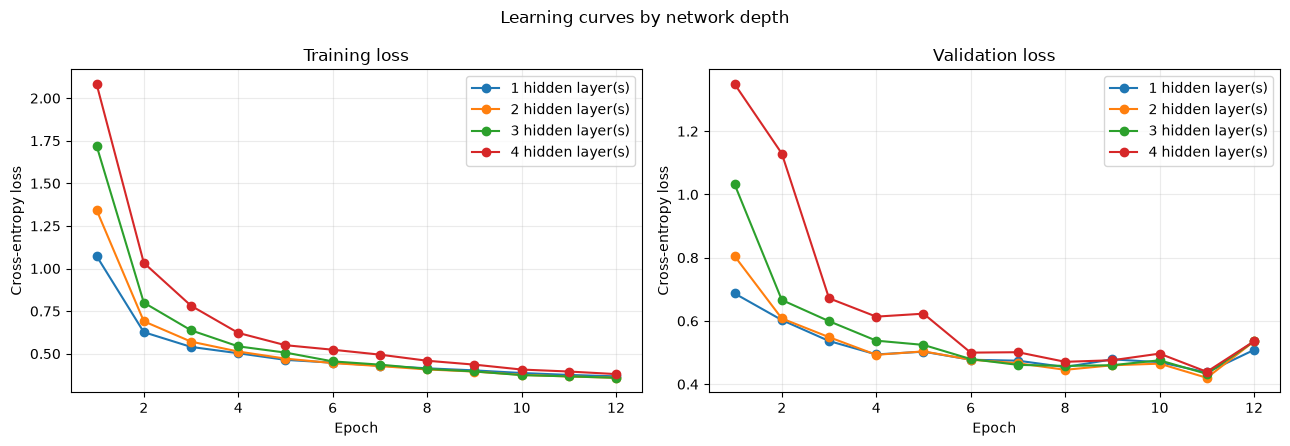

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for depth, h in results.items():
    epochs = np.arange(1, len(h["train_loss"]) + 1)
    axes[0].plot(epochs, h["train_loss"], marker="o", label=f"{depth} hidden layer(s)")
    axes[1].plot(epochs, h["val_loss"], marker="o", label=f"{depth} hidden layer(s)")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Validation loss", xlabel="Epoch", ylabel="Cross-entropy loss")
for ax in axes: ax.grid(alpha=0.25); ax.legend()
fig.suptitle("Learning curves by network depth")
fig.tight_layout()
plt.show()

**Figure 1 caption.** Training (left) and validation (right) cross-entropy loss by epoch for each depth. Use the curves to compare convergence and identify any validation-loss increase that may signal overfitting. Interpret the plotted results after running the notebook; no outcome is assumed in advance.

**Accuracy across training**

Accuracy is the fraction of images classified correctly. Plotting both training and validation accuracy helps reveal whether a model's improvement on the training data also transfers to validation images.

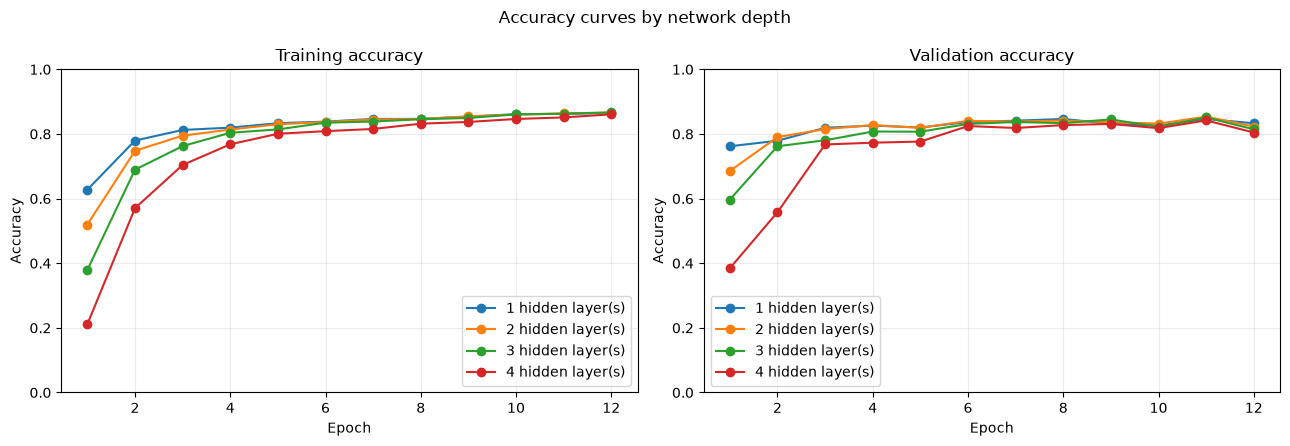

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for depth, h in results.items():
    epochs = np.arange(1, len(h["train_acc"]) + 1)
    axes[0].plot(epochs, h["train_acc"], marker="o", label=f"{depth} hidden layer(s)")
    axes[1].plot(epochs, h["val_acc"], marker="o", label=f"{depth} hidden layer(s)")
axes[0].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
for ax in axes: ax.grid(alpha=0.25); ax.legend()
fig.suptitle("Accuracy curves by network depth")
fig.tight_layout()
plt.show()

**Figure 2 caption.** Training (left) and validation (right) accuracy by epoch. The separation between training and validation curves indicates how differently the models perform on the data they learn from and the held-out validation subset.

**End-of-run comparison**

The summary table and plots below report measured outcomes from this notebook run. Training time is hardware-dependent, so it should be interpreted as a relative comparison from the same machine and session.

In [7]:
summary_df.style.format({
    "final_train_acc": "{:.3f}", "final_val_acc": "{:.3f}",
    "final_train_loss": "{:.3f}", "final_val_loss": "{:.3f}", "seconds": "{:.1f}"
})

,depth,parameters,final_train_acc,final_val_acc,final_train_loss,final_val_loss,seconds
0,1,101770,0.865,0.833,0.367,0.508,20.8
1,2,118282,0.866,0.823,0.359,0.535,20.4
2,3,134794,0.867,0.815,0.358,0.535,21.1
3,4,151306,0.861,0.804,0.380,0.536,21.9


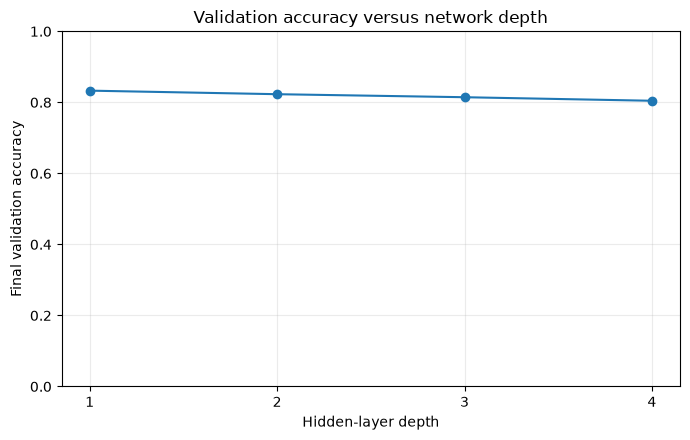

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(summary_df["depth"], summary_df["final_val_acc"], marker="o")
ax.set(xlabel="Hidden-layer depth", ylabel="Final validation accuracy",
       title="Validation accuracy versus network depth", xticks=DEPTHS, ylim=(0, 1))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Figure 3 caption.** Final validation accuracy against hidden-layer depth, based on the measured run. It is useful for spotting whether performance gains continue as layers are added; read it alongside the loss curves and training-time table rather than treating accuracy alone as the full story.


### What did depth change?

The results show that increasing the number of hidden layers did not improve the model's validation performance. Instead, the model with only **1 hidden layer achieved the highest validation accuracy of 83.30%**, while the deeper models showed a gradual decrease in performance.

#### Validation Accuracy

| Hidden Layers | Training Accuracy | Validation Accuracy |
|---|---:|---:|
| 1 | 86.53% | 83.30% |
| 2 | 86.59% | 82.30% |
| 3 | 86.68% | 81.45% |
| 4 | 86.08% | 80.45% |

The 1-hidden-layer model performed best on unseen validation data. Although the training accuracy remained relatively similar across all models, validation accuracy decreased as more layers were added. This suggests that additional depth did not provide useful improvements for this particular dataset and training setup.

#### Training Loss and Validation Loss

The deeper models did not achieve better final validation loss. The 1-layer model obtained a validation loss of **0.5084**, compared with 0.5353 for 2 layers, 0.5354 for 3 layers, and 0.5357 for 4 layers.

This indicates that the shallowest model not only classified more validation images correctly but also produced better overall validation predictions based on the loss measurement.

#### Training Time and Model Complexity

Adding more hidden layers increased the number of parameters and slightly increased training time.

| Hidden Layers | Parameters | Training Time |
|---|---:|---:|
| 1 | 101,770 | 20.79 s |
| 2 | 118,282 | 20.42 s |
| 3 | 134,794 | 21.14 s |
| 4 | 151,306 | 21.88 s |

The 4-layer model had the most parameters (151,306) and took the longest to train (21.88 seconds). However, it achieved the lowest validation accuracy at 80.45%. This demonstrates that increasing model complexity does not necessarily lead to better classification performance.

### Overall Discussion

Based on the experiment, increasing network depth did not improve Fashion-MNIST classification performance. The 1-hidden-layer model provided the best balance between validation accuracy, validation loss, and model complexity.

One possible explanation is that the dataset and the selected training configuration did not require a deeper network to learn useful features. Adding more layers increased the model's capacity without producing better generalization to the validation data.

However, these results are limited to one random seed, a subset of Fashion-MNIST, and the selected training settings. Since deeper models also had more parameters, the experiment does not isolate depth from model capacity completely.

**Conclusion:** For this experiment, a deeper neural network was not necessarily better. The shallow model achieved the strongest validation performance with fewer parameters, showing that choosing an appropriate network architecture is more important than simply increasing the number of layers.


The theory gives reasons to expect both benefits and costs. More layers allow a network to compose transformations and may represent some patterns more efficiently. But more depth adds trainable parameters and computation, and gradients must pass through more layers. With this plain MLP and this fixed optimizer, deeper models might train less smoothly or need a different tuning strategy. A finding that extra depth did not help would still be useful: it would show that architectural complexity alone does not guarantee a better result under the chosen training conditions.

## Takeaway

1. **More layers are not automatically better.** Evaluate whether added depth improves validation results, not only training performance.
2. **Learning curves tell a richer story than one final score.** Loss and accuracy trends can reveal slow learning, instability, or overfitting.
3. **Compare gains against cost.** If a deeper model adds training time and parameters for little validation improvement, a shallower architecture may be the more practical choice.

The key result of this experiment is not a universal “best depth.” It is evidence about how depth behaved under a clearly stated, reproducible setup—and a reminder that architectural choices should be tested rather than assumed.

## References

1. **Similar Experimentation:** [Effect of Depth on Rank and Learning (NeurIPS 2020)](https://proceedings.neurips.cc/paper/2020/file/d5ade38a2c9f6f073d69e1bc6b6e64c1-Paper.pdf) – An experiment investigating how the number of hidden layers affects the learning performance of MLPs using Fashion-MNIST.

2. **Dataset API:** [PyTorch – FashionMNIST Documentation](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html) – Official documentation for loading and using the Fashion-MNIST dataset.



---


## Reproducibility 

The complete experiment code is available in this GitHub repository:

**[View the Jupyter Notebook on GitHub](https://github.com/kthrynlgh/martinito-ds-portfolio/blob/main/assignments/assignment-01.ipynb)**

**Note:** Results may vary slightly depending on the random seed, hardware, and execution environment. Running all cells from top to bottom reproduces the experiment and generates the figures and measured summary table.
